# 5.2. pandas: Data Wrangling

Module M-227-04: Programming for Data Analytics

Instructor: Nadežda Zeņina

Course author: Dmitry Pavlyuk

### If you know Excel, you already know these operations

| pandas | What you did in Excel |
|---|---|
| `pd.concat([a, b])` | copy the rows of one worksheet under another |
| `pd.merge(a, b, on="id")` | `VLOOKUP` / `XLOOKUP` - fetch columns from another sheet by a key |
| `groupby("col").mean()` | a PivotTable - one summary row per category |
| `melt` / `pivot` | turn several measure columns into rows, and back |
| hierarchical index | row labels with two levels (group → student), like grouped rows in a PivotTable |

Keep this table in mind: every section today is one of these five, done in one line of code instead of twenty clicks.

## Data manipulation

* Hierarchical indexing (multi-index)
* Data reshaping
* Joining data frames
* Data aggregation

## Example data set: Students

4 dataframes:
* __courses__ stores information about available courses
* __groups__ stores information about student groups
* __students__ stores information individual students
* __results__ stores information about course attendance by students and grades

Four tables, each about one kind of thing; the id columns link them - the way a database (or a well-organised Excel workbook) stores data
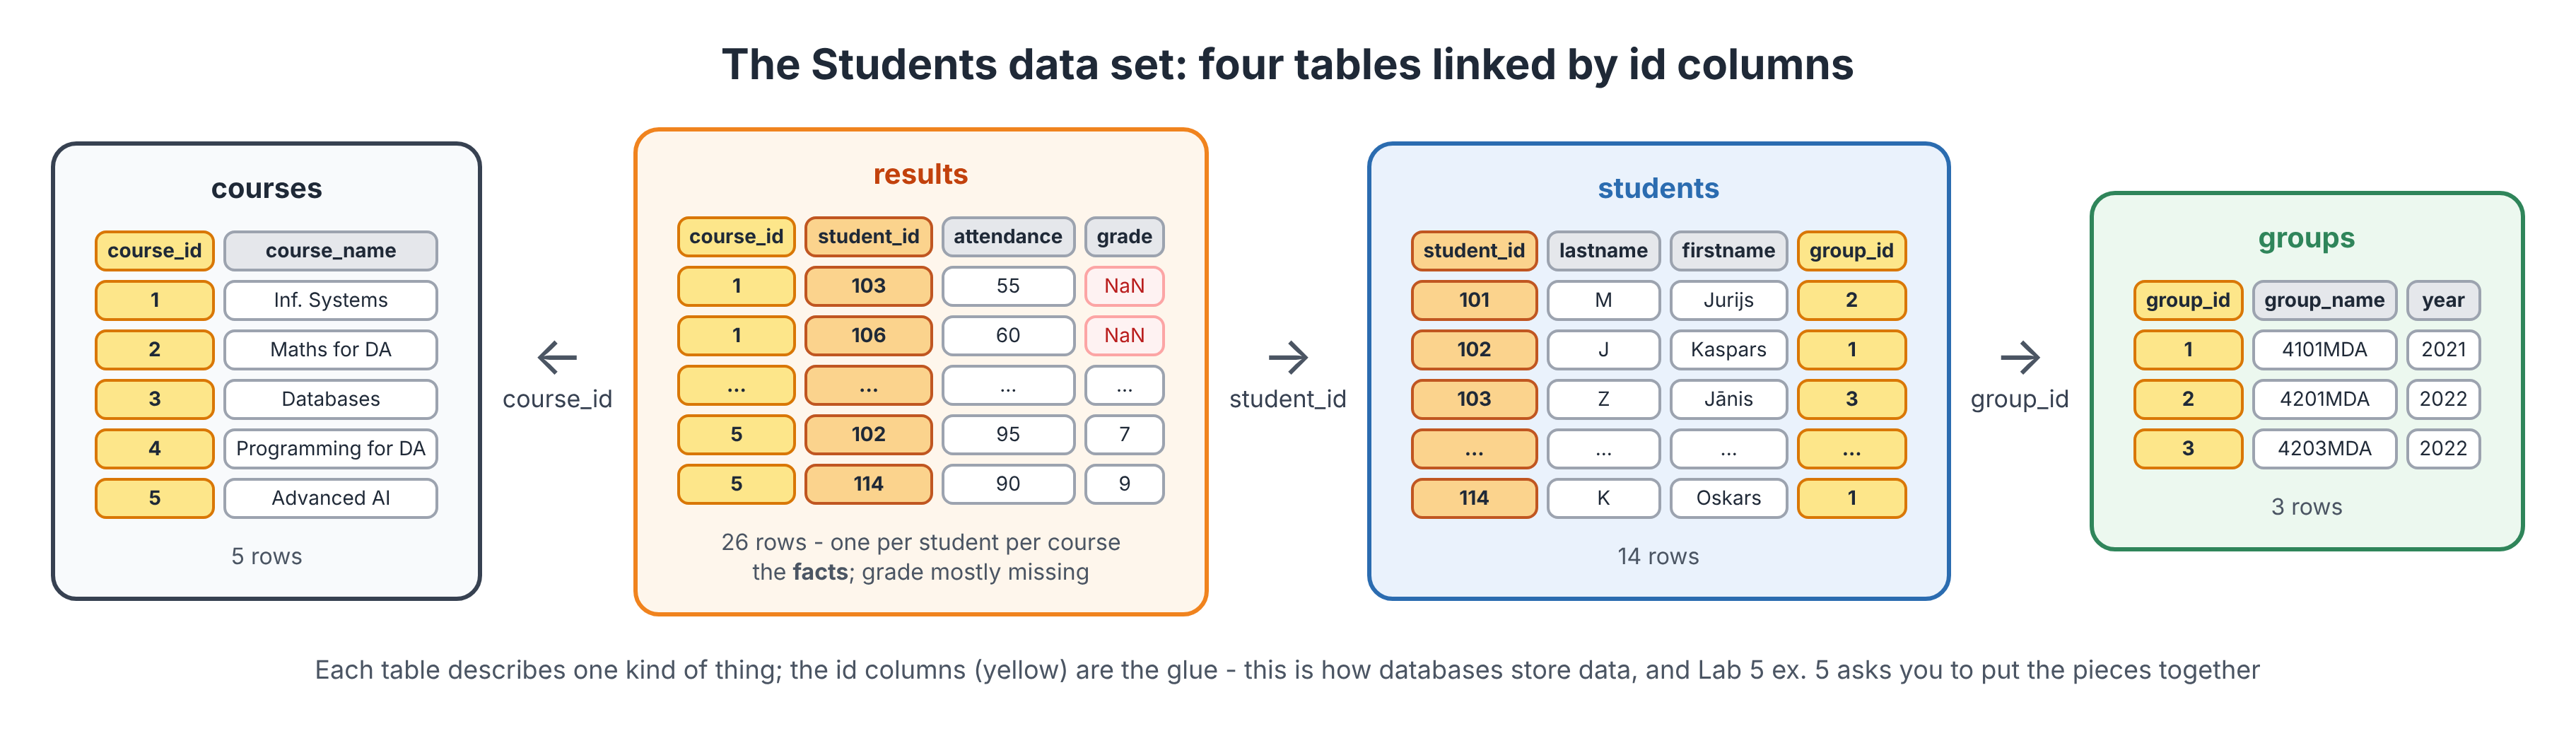

In [ ]:
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ["st_courses.csv", "st_groups.csv", "st_students.csv", "st_results.csv", "bikes.csv"]:
    urllib.request.urlretrieve("https://raw.githubusercontent.com/nzenina2/python-da-main-nz/main/week5/data/" + name, "data/" + name)
print(os.listdir("data"))

## Example data set

* Loading __courses__

In [ ]:
import pandas as pd
import numpy as np
courses_df = pd.read_csv('data/st_courses.csv')
courses_df.head()

* Loading __groups__

In [ ]:
groups_df = pd.read_csv('data/st_groups.csv')
groups_df.head()

## Example data set

* Loading __students__

In [ ]:
students_df = pd.read_csv('data/st_students.csv')
students_df.head()

* Loading __results__

In [ ]:
results_df = pd.read_csv('data/st_results.csv')
results_df.head()

### Data quality check first

Look at `results`: a `grade` of `NaN` means *no final grade yet* - most students have attended but not been graded. Before wrangling, three quick checks on every table: how big is it, where are the gaps (`isna`)

In [ ]:
for df in [students_df, groups_df, courses_df, results_df]:
    df.info()
    print()


In [ ]:
for df in [students_df, groups_df, courses_df, results_df]:
    display(df.isna().sum())

### Recall indexes

We already discussed one-sequence indexes in the previous presentation:

In [ ]:
students_df.set_index("student_id", inplace=True)
students_df.head()

In [ ]:
groups_df.set_index("group_id", inplace=True)
courses_df.set_index("course_id", inplace=True)

### Hierarchical indexing

Indexes in pandas data frames are not limited by one sequence:

In [ ]:
results_df = results_df.set_index(["course_id","student_id"]).sort_index()
results_df.head(18)

`set_index` with a **list** of two columns builds a two-level index; `sort_index()` orders the rows by course, then by student. The blank cells under `1` are not missing values - they are the same course label, not repeated for readability.

## Joining data frames

### Concatenate

Concatenating data frames along with an axis and performing optional set logic (union or intersection) of the indexes on the other axes.

concat stacks tables under each other (default) or side by side (axis=1); join='inner' keeps only the common columns, keys= marks where rows came from
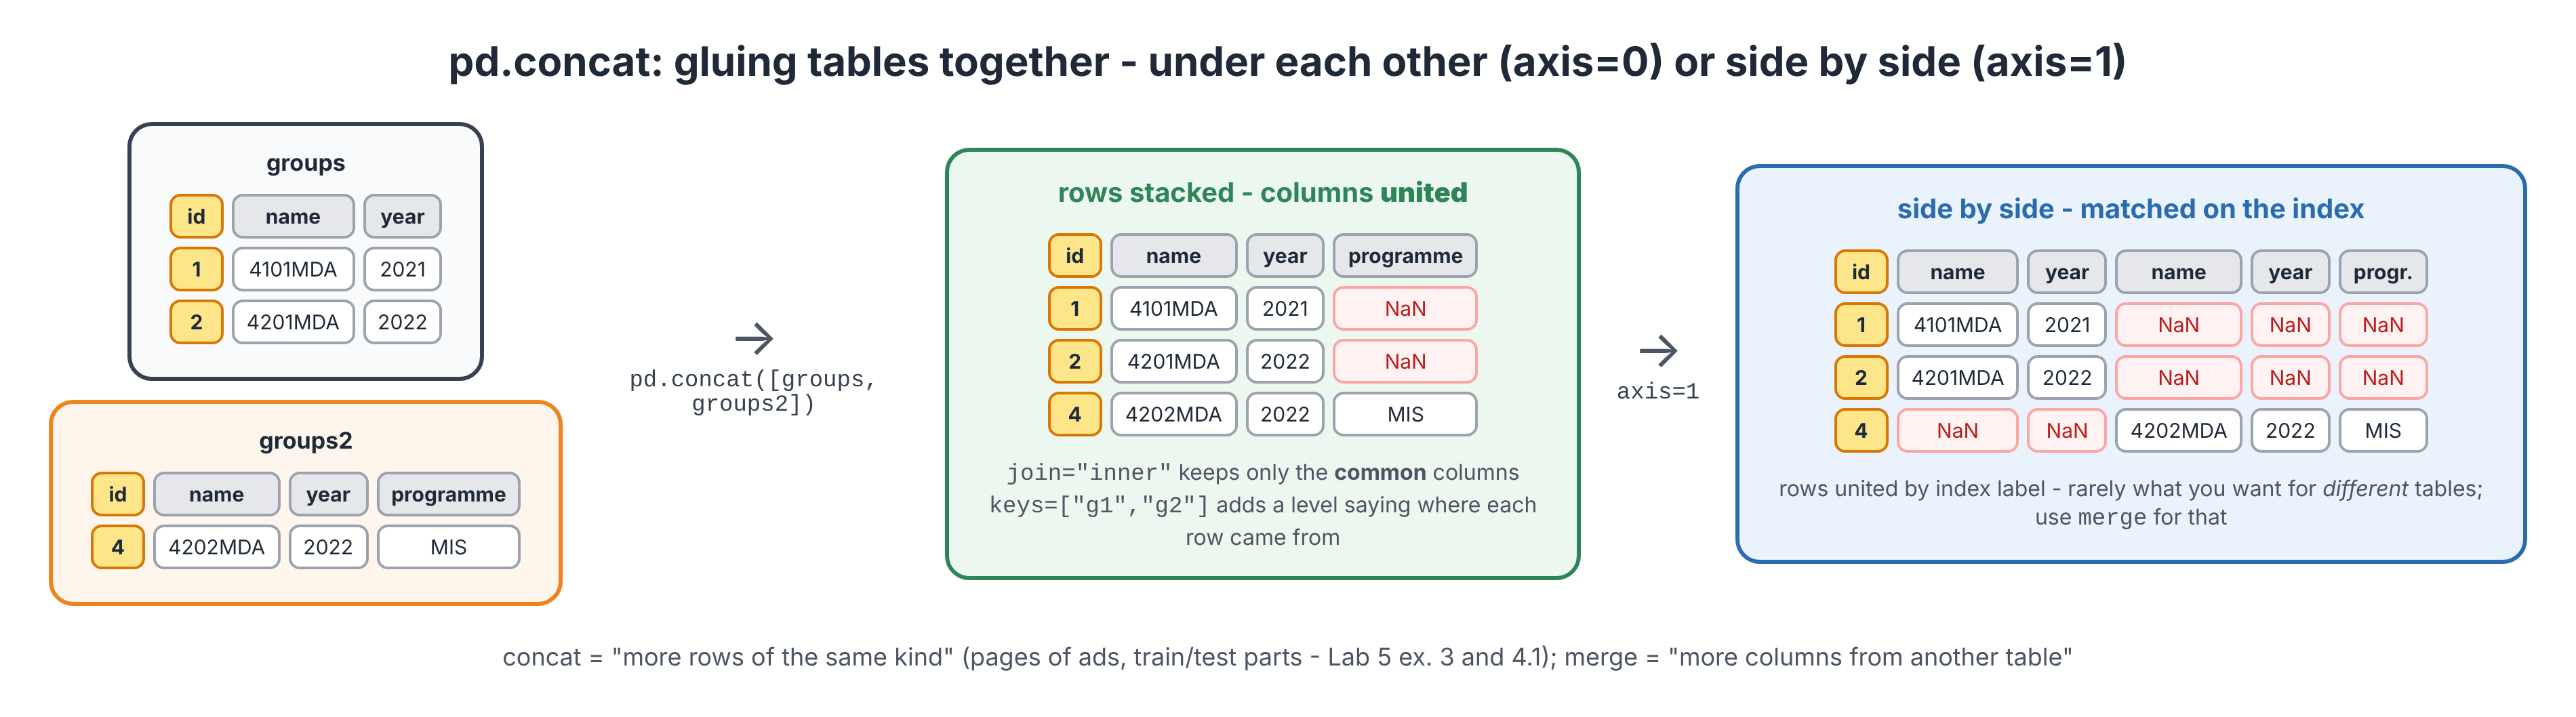

In [ ]:
groups_df

In [ ]:
groups2_df=pd.DataFrame({'group_id':[4],'group_name':['4202MDA'], 'group_year_started':[2022], 'programme':['MIS']})
groups2_df.set_index('group_id', inplace=True)
groups2_df

A new group arrived in a second table - with one extra column `programme` that the first table does not have. The typical situation: data for the same thing delivered in several files (one per month, one per web page, one per department).

### Concatenate

* Concatenating rows and creating __union__ of columns (with NaN if necessary)

In [ ]:
pd.concat([groups_df,groups2_df])

* Concatenating rows and creating __intersection__ of columns

In [ ]:
pd.concat([groups_df,groups2_df], join="inner")

Default: **all** columns are kept and the missing ones filled with `NaN` (*union*). `join="inner"`: only the columns present in **every** table survive (*intersection*) - `programme` disappears. `concat` takes a **list** of DataFrames - two, or twenty pages of advertisements (Lab 5, exercise 4.1).

### Concatenate

* Concatenating rows and introducing indexes to distinguish data frames

In [ ]:
pd.concat([groups_df,groups2_df], join="inner", keys=['g1','g2'])

`keys` adds an outer index level that remembers **which table each row came from** - a two-level index again.

### Concatenate

* Concatenating columns and creating __union__ of rows

In [ ]:
pd.concat([groups_df,groups2_df], axis=1)

`axis=1` glues the tables **side by side**, matching rows by index label. Here the labels do not overlap (1-3 vs 4), so every row is half `NaN` - rarely what you want for two *different* tables. For that there is `merge`.

In [ ]:
groups_df=pd.concat([groups_df,groups2_df], join="inner").reset_index()

groups_df

From here on `groups_df` contains the four groups (and `group_id` is a column again).

### Merge - database-style joins

* INNER JOIN
* LEFT (OUTER) JOIN
* RIGHT (OUTER) JOIN
* CROSS (FULL) JOIN

<img src="https://raw.githubusercontent.com/DmitryPavlyuk/python-da/main/week5/img/sql-table-joins.png">

merge matches rows of two tables on a common column; how= decides what happens to rows without a partner
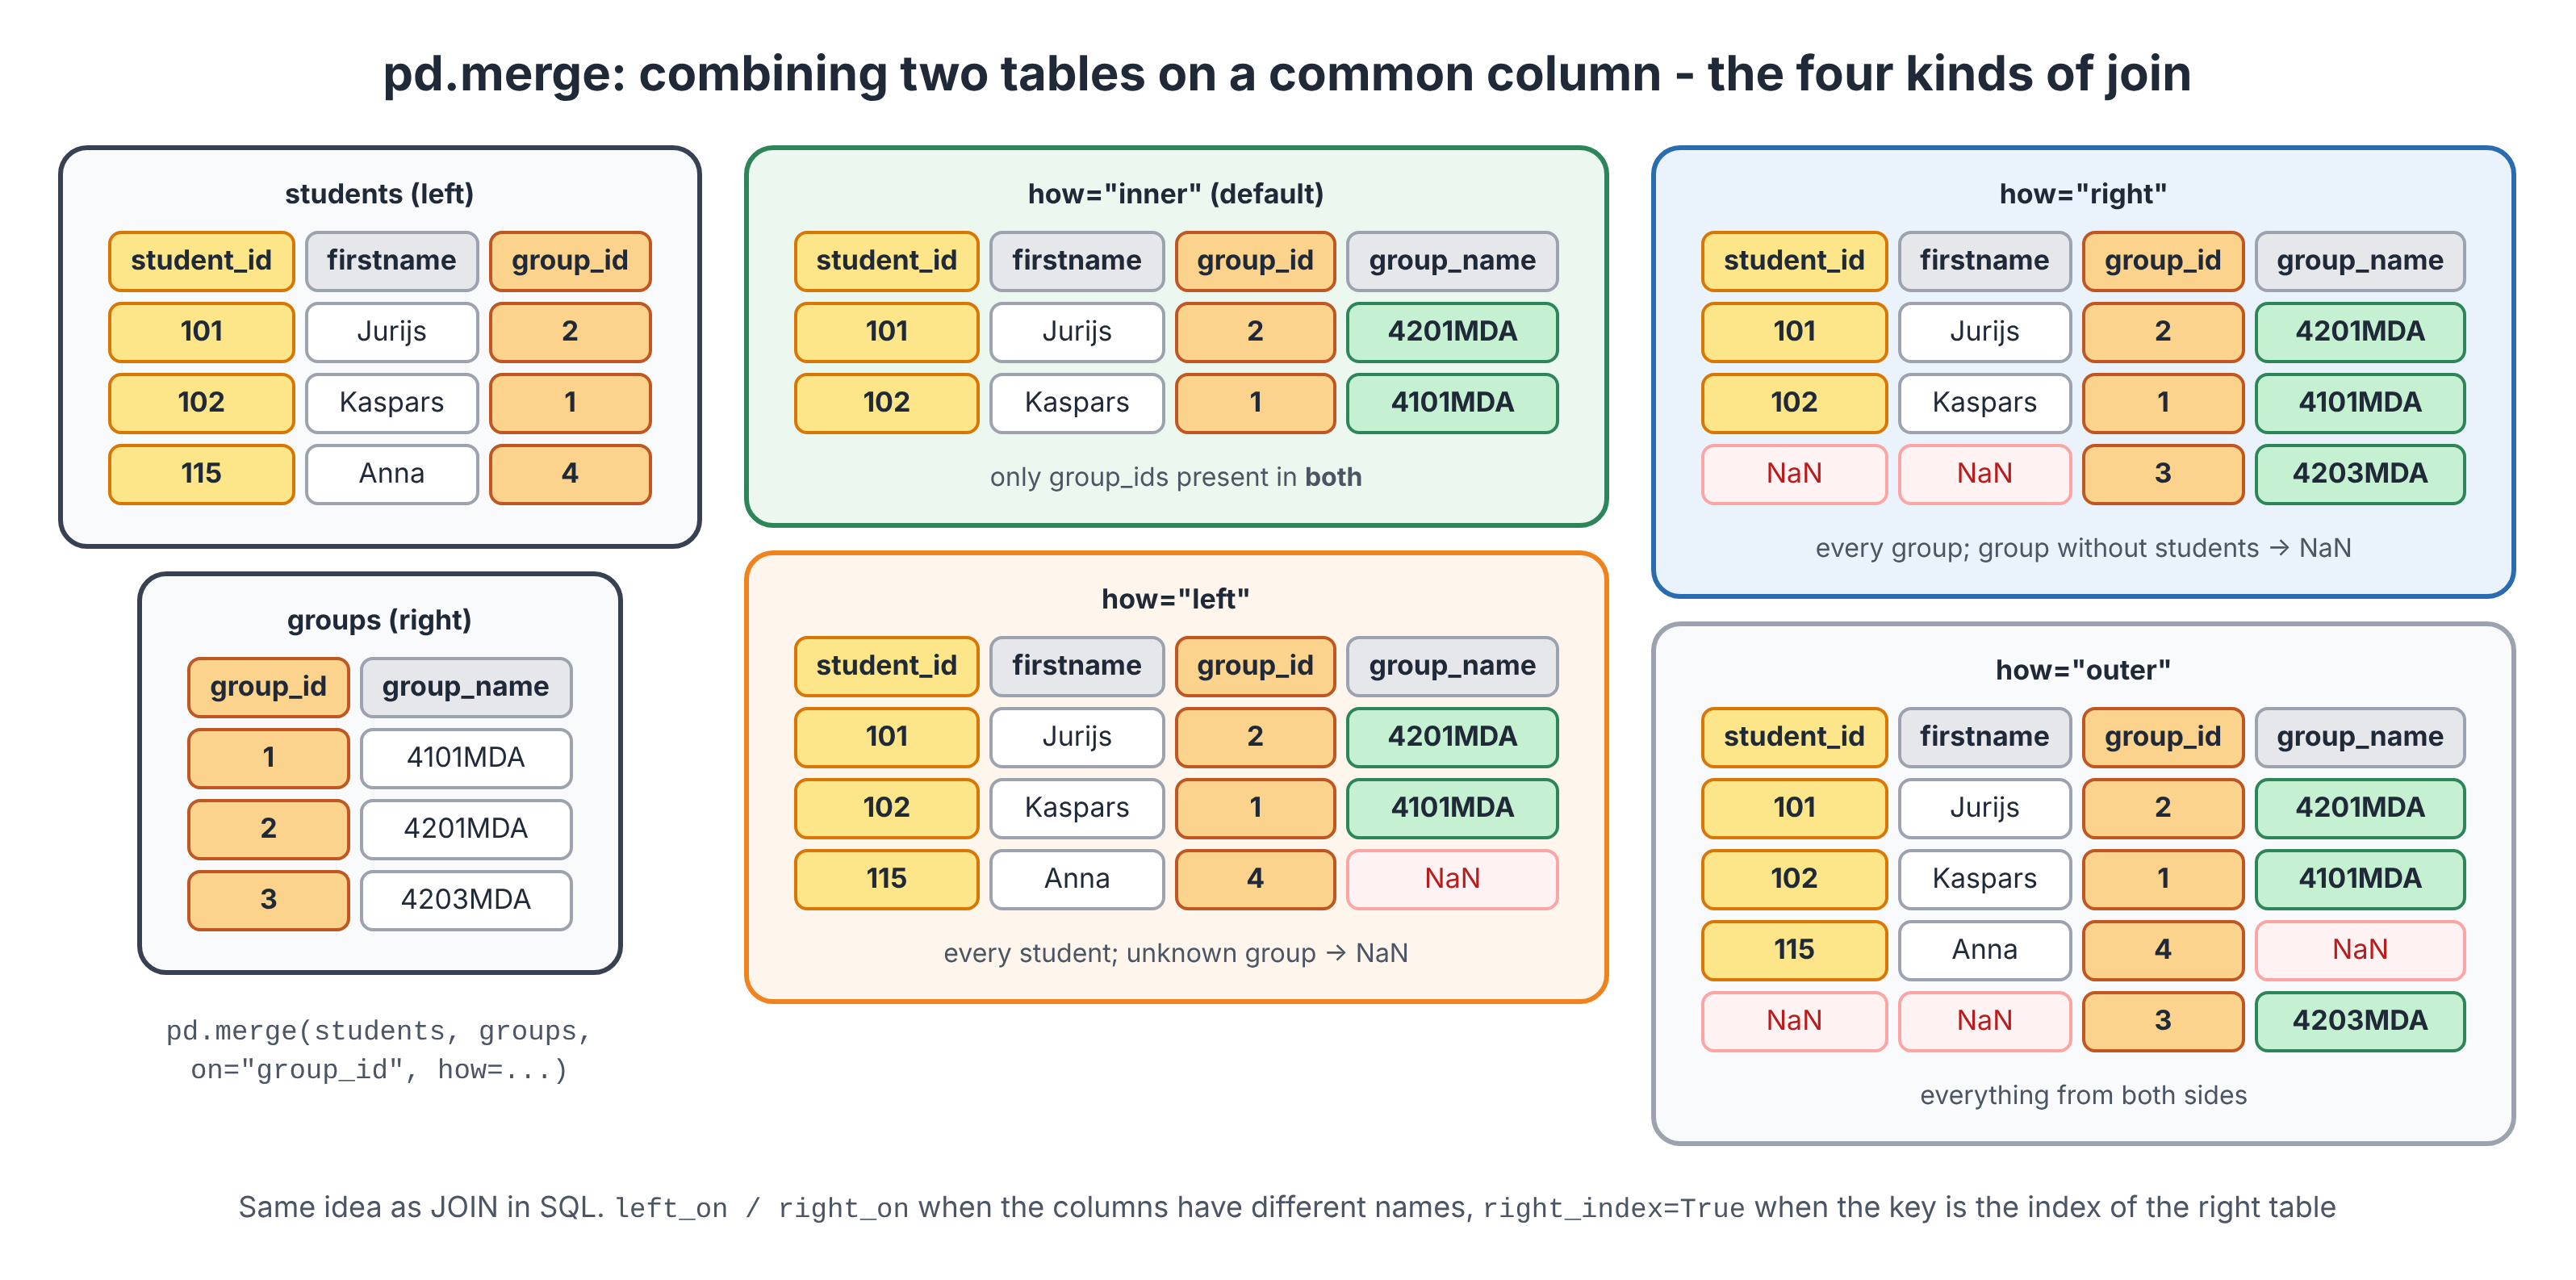

`merge` answers "**add the columns of that table to this one**, matching on a key". The key is `group_id` in both `students` and `groups`. `how` decides what to do with rows that have no partner: `inner` (default) drops them, `left` keeps every row of the left table, `right` every row of the right table, `outer` keeps everything. If you know SQL, this is `JOIN`; if you know Excel, this is `VLOOKUP` done properly.

A note on the last bullet above: in SQL a **FULL OUTER JOIN** (pandas `how="outer"`: all rows from both sides) and a **CROSS JOIN** (pandas `how="cross"`: every row of the left paired with every row of the right) are two different operations; `how="outer"` is the one you will use.

### Inner join

In [ ]:
groups_df.set_index("group_id", inplace=True)
results_df.reset_index(inplace=True)
pd.merge(students_df, groups_df, left_on="group_id", right_index=True)

`left_on="group_id"` - the key column on the left (`students_df`), `right_index=True` - on the right the key *is* the index. Every student got the name and the start year of their group. Group 4 has no students, so it does not appear: **inner** = only matches. (The first two lines are preparation: `groups_df` gets its index back, and `results_df`'s two index levels become ordinary columns for the merges below.)

### Right outer join

In [ ]:
pd.merge(students_df, groups_df, left_on="group_id", right_index=True, how="right").tail()

`how="right"`: every group is kept - the last row is group 4 with `NaN` student data.

### Left outer join

In [ ]:
pd.merge(students_df, results_df, left_on="student_id", right_on="student_id", how="left").head()

Students joined with their results: `left_on` / `right_on` because the key is `student_id` on both sides (`on="student_id"` is the short form when the names agree; here the left key is the index of `students_df`, which pandas accepts). `how="left"` keeps **every student**, also one who has no results yet (they would show `NaN` in `course_id`, `attendance`, `grade`). A student with three results appears three times - a join can **multiply rows**, so always compare `shape` before and after.

### YOUR TURN 1: joining tables

1. Merge `results_df` with `courses_df` (key `course_id`; on the right it is the index → `right_index=True`). Show the first 5 rows.




In [ ]:
# YOUR CODE HERE:

In [ ]:
# 1.
res_named = pd.merge(results_df, courses_df, left_on="course_id", right_index=True)
print(res_named.head())



## Data aggregation

### Data aggregation

Aggregation refers to the process by which entities are combined to form a single meaningful entity.
Aggregation in Pandas and databases are fairly the same - refer __GROUP BY__ of SQL.

groupby splits the table into groups, applies a statistic to each group and combines the results into one row per group
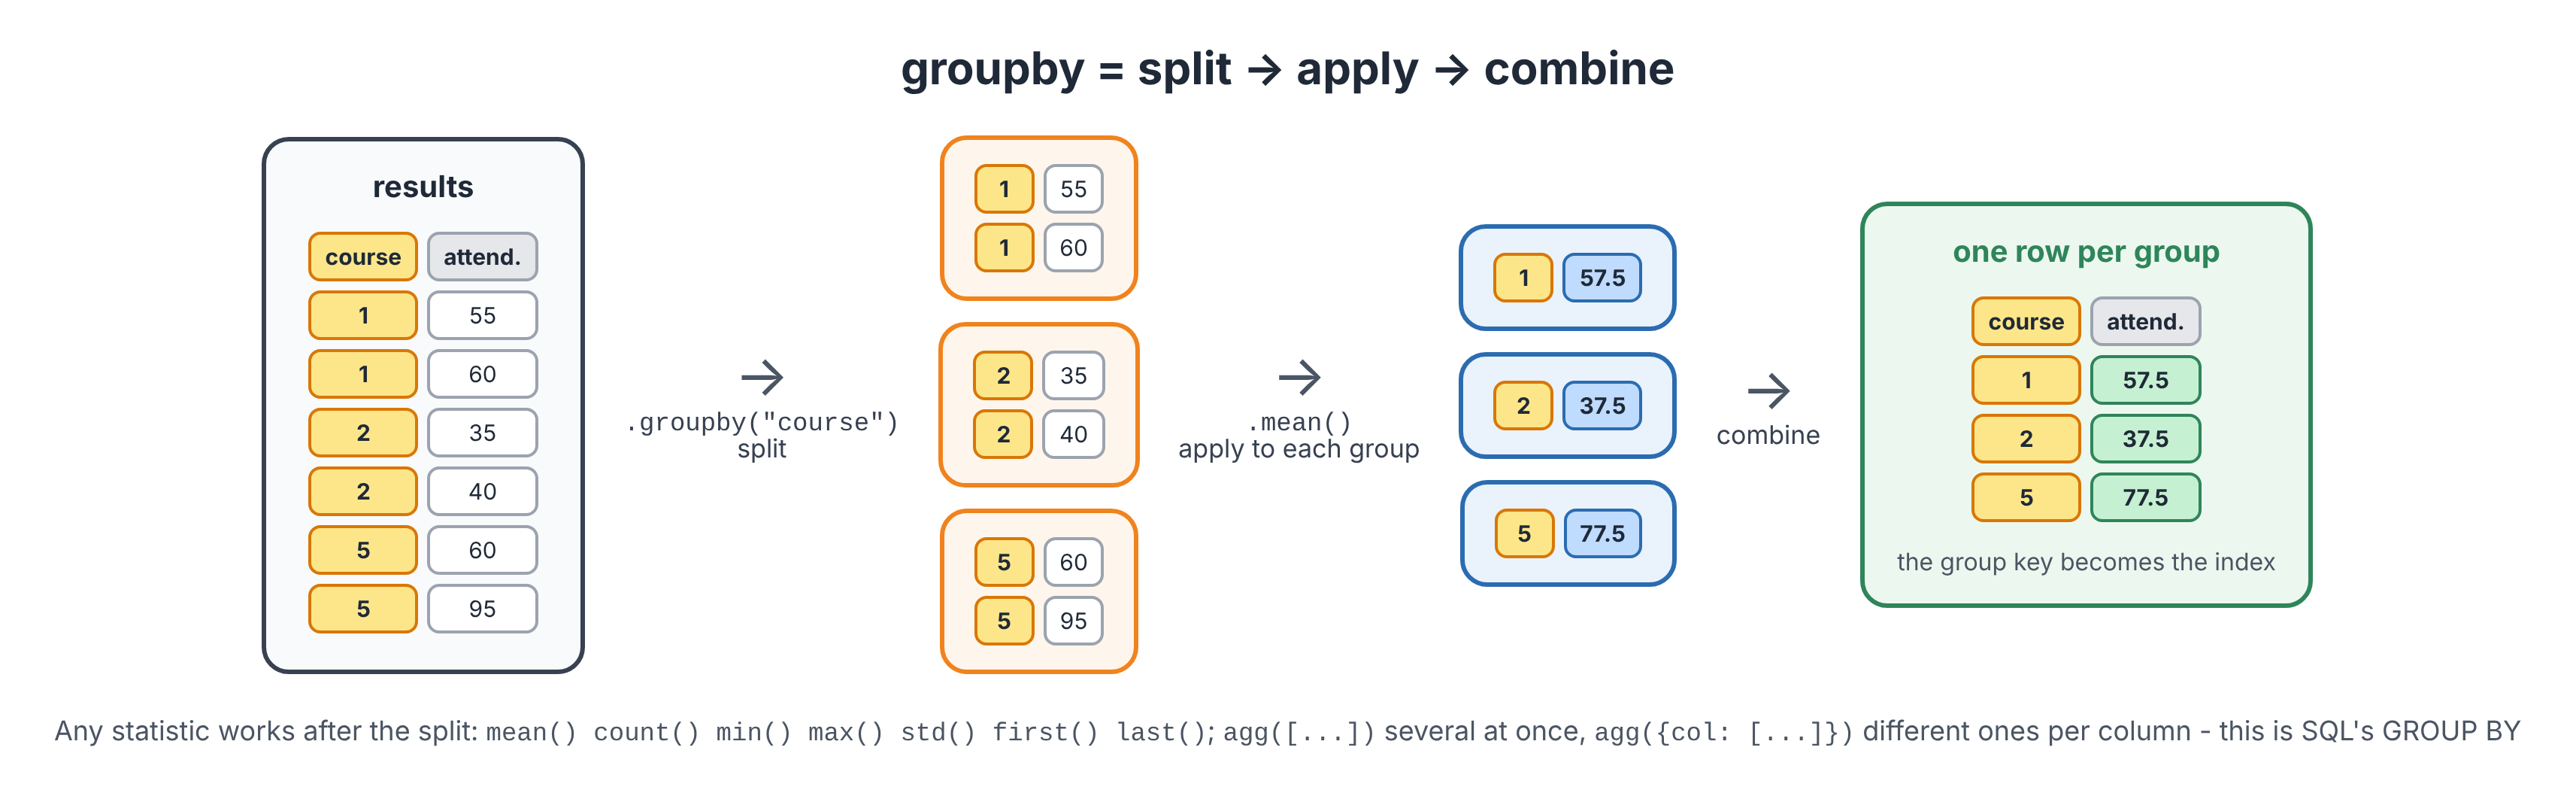

Three steps, always the same: **split** the rows into groups by a key (course), **apply** a statistic to each group (mean attendance), **combine** the answers into one row per group. In Excel this is a PivotTable; in SQL it is `GROUP BY`. Housekeeping first - back to the (course, student) index:

In [ ]:
results_df.columns.name=None
results_df.reset_index(inplace=True)
results_df.set_index(["course_id","student_id"], inplace=True)
results_df.head(18)

The extra column `index` is a left-over of calling `reset_index()` twice (the old 0...25 numbering became a column) - harmless for the statistics below; we drop it before reshaping.

### Groupby

__.groupby__ creates a special object for easy access to groups and calculating within-statistics

In [ ]:
results_df.groupby("course_id")

In [ ]:
list(results_df.groupby("course_id"))[0]

`groupby` alone computes nothing - it only *prepares* the groups (one per course): that is the **split**. Turning it into a list shows the first group: the key `1` and the six rows of course 1. Normally you never look inside; you immediately ask for a statistic.

### Aggregation

* Statistical - max(), min(), mean(), sum(), std(), count()
* Element selection - first(), last(), head(), tail()
* Custom function  - agg()

### Statistical

In [ ]:
results_df.groupby("course_id").mean()

In [ ]:
results_df.groupby("course_id").count()

One row per course - **apply + combine**. `mean()` - the average attendance per course (course 2 is the least attended, 44 %); `grade` is `NaN` for courses without a single grade. `count()` counts **non-missing** values - 6 results per course but 0 grades, except course 5 with 3 grades. (`size()` would count rows including `NaN`.)

To aggregate **one column only**, select it first - this is the form you will write most often:

In [ ]:
results_df.groupby("course_id")["attendance"].mean().round(1)     # a Series: one number per course

### Element selection

In [ ]:
results_df.sort_values("attendance").groupby("course_id").last()

In [ ]:
results_df.sort_values("attendance").groupby("course_id").first()

Sort by attendance, then `last()` / `first()` per group - a quick way to see the highest and the lowest attendance in every course. **Careful with the other columns:** `first()` / `last()` take the first / last *non-missing* value **of each column separately**, so a row of the result can be assembled from different students. Look at course 5 in `first()`: attendance 50 belongs to student 105, but the grade 8.0 belongs to student 113 (105 has no grade). When you need the **whole record** of the lowest / highest student, use `nth(0)` / `nth(-1)`, which return real rows:

In [ ]:
results_df.sort_values("attendance").groupby("course_id").nth(0)      # the real lowest-attendance row of each course

### Custom function

In [ ]:
results_df.groupby("course_id").agg(lambda x: max(x)- min(x))

In [ ]:
def myrange(x):
    return max(x)- min(x)
results_df.groupby("course_id").agg([min, max,myrange])

`agg` applies **your own function** to each group (here the range = max − min, with a `lambda` or a named function from week 3), or a **list** of functions at once - the result gets a two-level column index: column → statistic. (pandas 2.x prints a *FutureWarning* when the built-in `min` / `max` are passed; in your own code write them as strings - `"min"`, `"max"`, `"mean"` - which is also clearer.)

### Custom function

Flexible set of functions

In [ ]:
results_df.groupby("course_id").agg({"attendance":[min, np.mean], "grade":["count"]})

Note how functions can be passed - __min__, __np_mean__, __"count"__

A **dictionary** says which statistics for which column: minimum and mean attendance, number of grades. In your own code the string form is enough: `agg({"attendance": ["min", "mean"], "grade": ["count"]})`. Lab 5, exercise 2.4c asks for *min, max and standard deviation of temperatures by season* - exactly this pattern.

### Aggregation on the bikes data

The same operation on the data set from 5.1 - this is the shape of Lab 5, exercise 2.4. First load it and make `datetime` a real date (5.1):

In [ ]:
bikes = pd.read_csv('data/bikes.csv')
bikes["datetime"] = pd.to_datetime(bikes["datetime"], format='%d/%m/%Y %H:%M')
bikes["hour"] = bikes["datetime"].dt.hour
bikes.head(3)

In [ ]:
bikes.groupby("season")["count"].mean().round(1)          # split by season -> mean rentals per hour -> one number per season

In [ ]:
bikes.groupby("hour")["count"].mean().plot.line(color="red")           # ... by hour of the day - two rush-hour peaks

In [ ]:
bikes.groupby("season").agg({"temp": ["min", "max", "std"], "count": ["mean", "max"]}).round(1)

Three lines of code answer three analytics questions: **when** is demand highest (season - fall/summer; hour - 8 and 17-18, the commute), and **how variable** is the weather per season. Reading the first plot in plain English: *"Demand has two peaks on an average day, at 8 and at 17-18 - the system is used for commuting."* That is the sentence a data analyst delivers; `groupby` produced it.

In [ ]:
# registered users: two commute peaks; casual users: one broad afternoon peak (leisure)
bikes.groupby("hour")[["casual", "registered"]].mean().plot.line(
    color={"casual": "blue", "registered": "black"}
)

## Reshaping data

The same numbers can be arranged **long** (one row = one value, many rows) or **wide** (one row = one student, many columns). Nothing is computed when we reshape - we only decide where the labels live. Two pairs of tools: `unstack` / `stack` work on **index levels**, `melt` / `pivot` on **columns**; in Lab 5 you need `melt`. First the housekeeping promised above - drop the left-over `index` column:

In [ ]:
results_df = results_df.drop(columns="index")
results_df.head(3)

### Row index to column index

* Transfer a level from the row index to the column index (__unstack__)

unstack moves the inner row level to the columns (long → wide); stack moves it back (wide → long); gaps become NaN
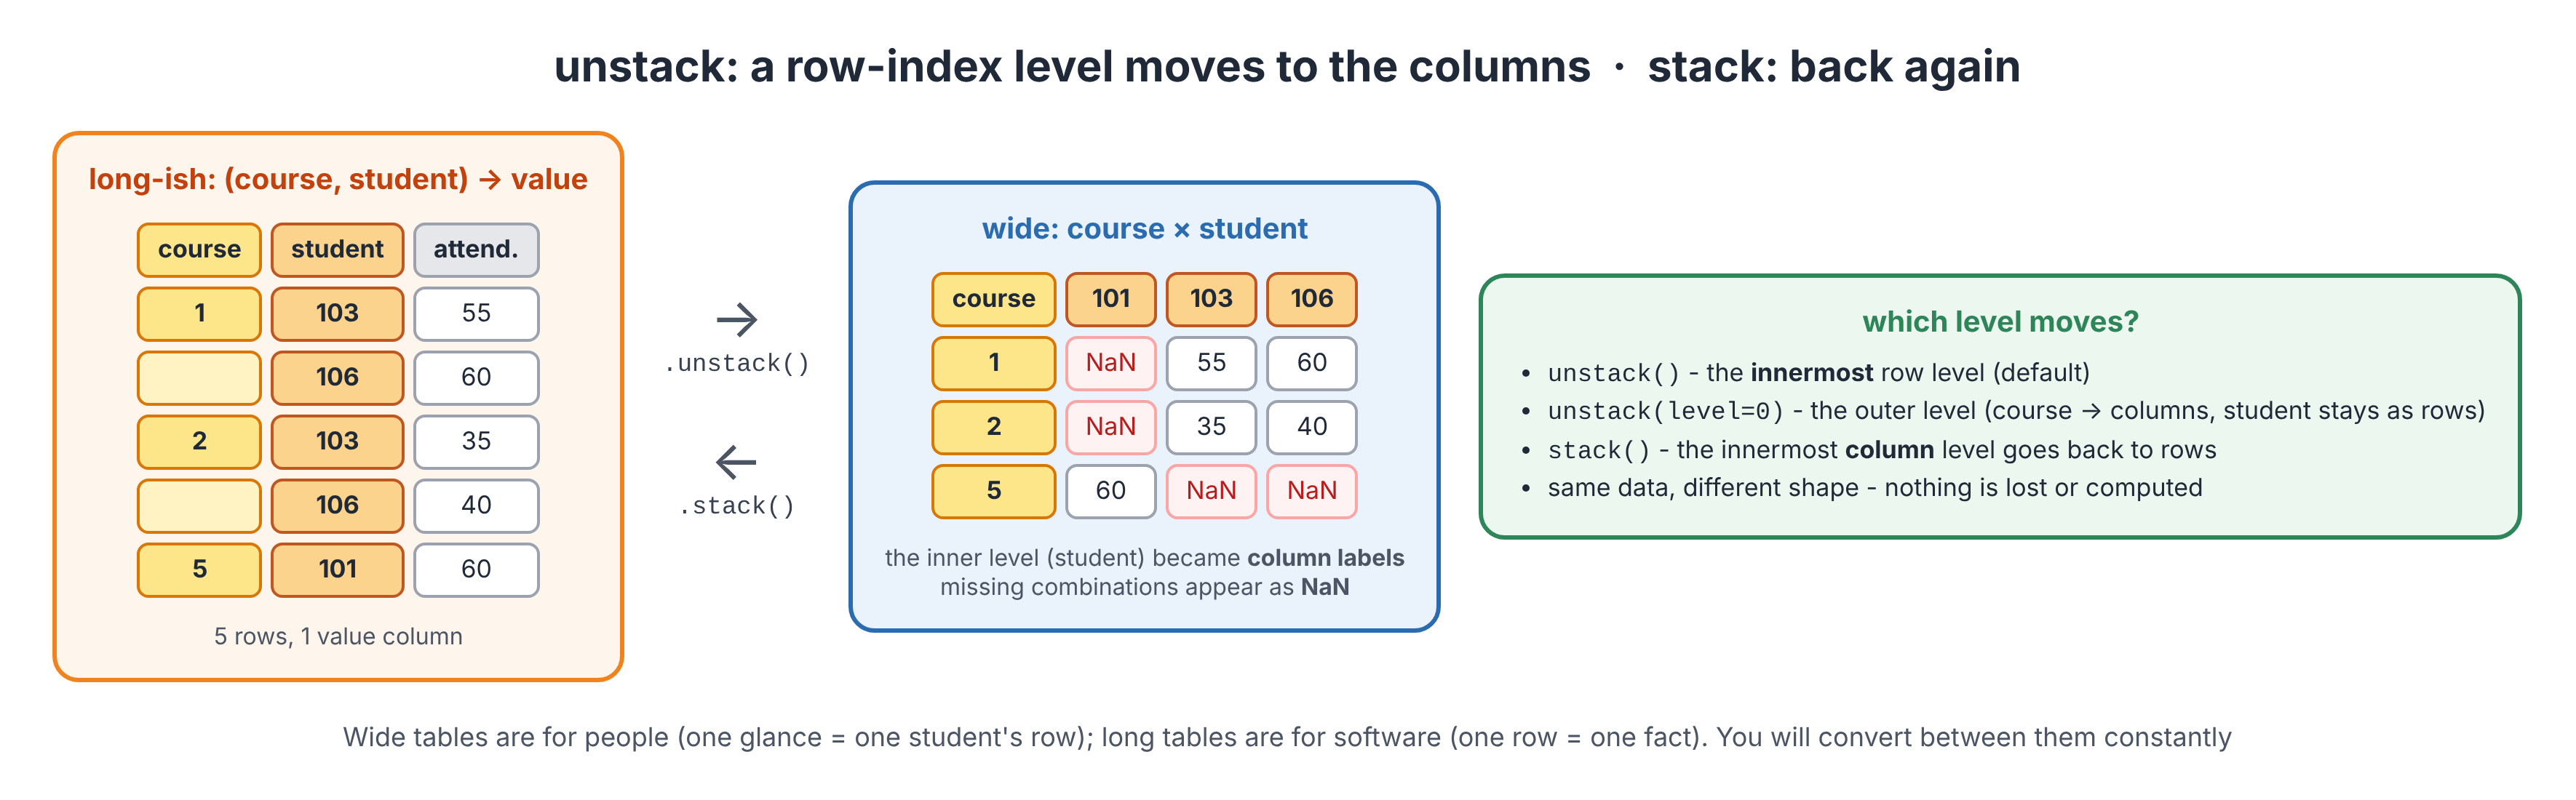

In [ ]:
results_df.unstack()

Students became **columns**: one row per course and one column per student (for each of `attendance` and `grade`). Many cells are `NaN` - student 101 never took course 1, so that combination does not exist. This *wide* layout is what you would build in Excel to look at the data; the *long* layout we started from is better for storage and computation.

In [ ]:
df1 = results_df.unstack(level=0)
df1.head()

`level=0` moves the **outer** level (course) to the columns instead: one row per student, one column per course - the grade sheet of each student. Note the two-level **column** index: indicator (`attendance` / `grade`) on top, course below.

### Column index to row index

* Transfer a level back from the column index to the row index (__stack__)

In [ ]:
df1.stack().head()

`stack` moves the inner column level (course) back down into the rows. It is *almost* the inverse of `unstack`: the values are unchanged, but combinations that were `NaN` in the wide table are **dropped** by default, so a table with gaps does not come back identical. (pandas 2.2 prints a *FutureWarning* about a new implementation of `stack` - a hint, not an error.)

### Long data

Potentially, we can move all column index levels into rows, so every row will contain only a single observation:

In [ ]:
results_df.columns.name="indicator"
results_df.stack()

Now **every row holds exactly one number**: course, student, which indicator, value - the *longest* possible layout (a Series with a three-level index). `results_df.columns.name = "indicator"` gives the column level a name, so that the new index level is called `indicator` and not `None`.

### Long data - melt

Similarly, we can do the same operation (but for columns, not indexes) using __melt__

melt turns the indicator columns into rows (one value per row); pivot turns them back into columns
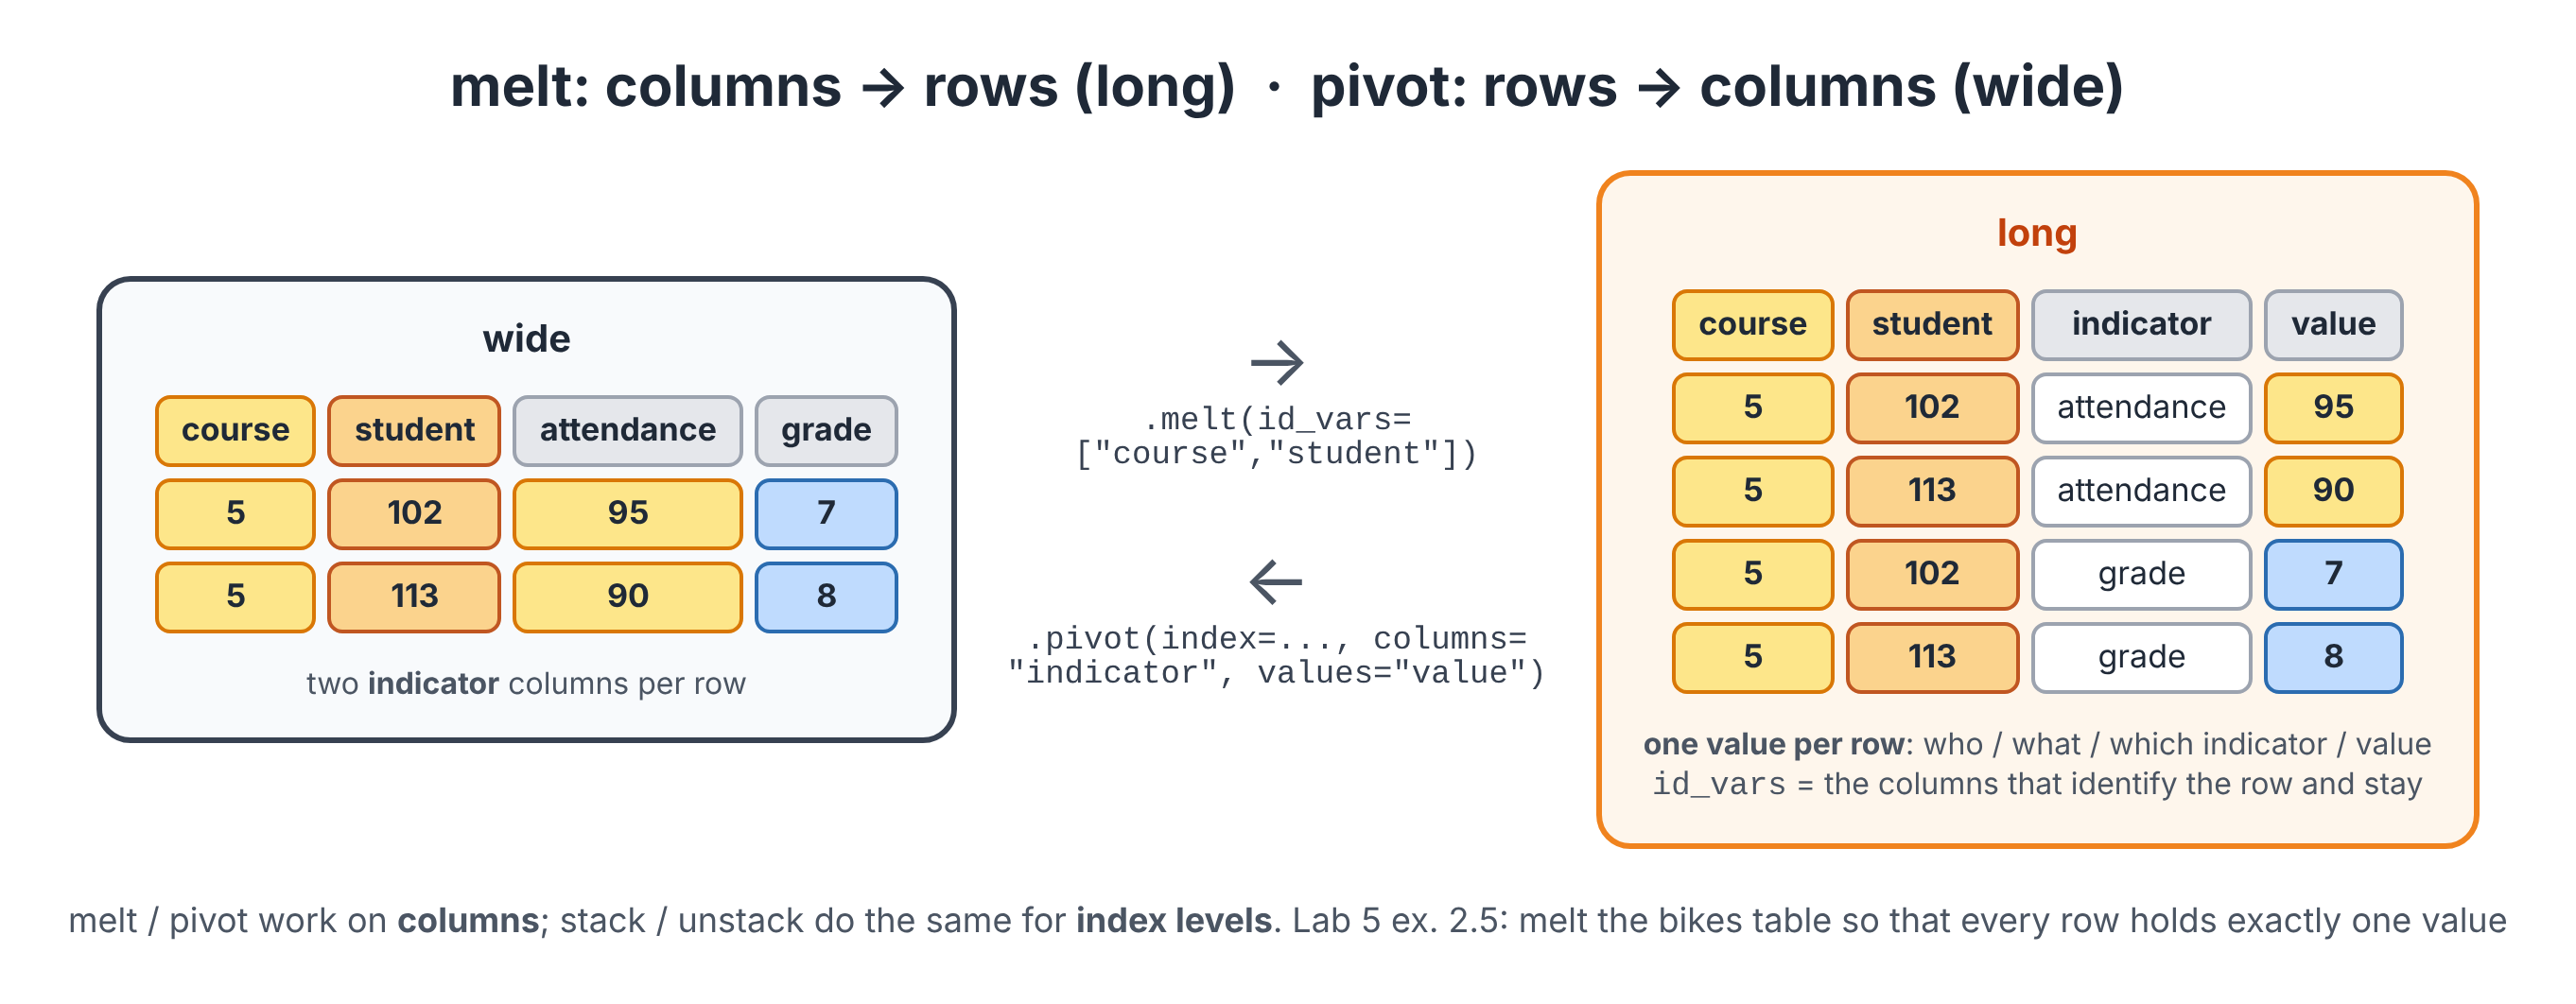

In [ ]:
results_long = results_df.reset_index().melt(id_vars=["course_id", "student_id"]).dropna()
results_long.head()

`melt` works on ordinary **columns** rather than index levels, so first `reset_index()` turns the two index levels into columns. `id_vars` names the columns that *identify* a row and must stay; every other column (`attendance`, `grade`) is turned into a pair of new columns: `indicator` (the old column name) and `value`. `.dropna()` removes the rows with a missing grade.

### Long data - reasons

* Efficient storage of sparse data (many NaN values)
* Adding new indicator (value in a column) is possible without changing the table structure
* Iterating over one dimension can be more efficient (thus, many third-party functions require long data)

In practice you will meet long data whenever you export from a database or a measurement system (one row per sensor per minute), and wide data whenever a person made the table in Excel. Plotting libraries (6.1) and statistical models (8.1) usually want **long**; people reading a report want **wide**.

### Wide data - pivot

__pivot__ operation is an inverse to __melt__ (like __stack/unstack__, but for columns)

In [ ]:
results_long.pivot(index=["course_id","student_id"], columns=["indicator"],values="value").head(18)

Three arguments, always the same questions: *what identifies a row* (`index`), *which column's values become the new column names* (`columns`), *which column holds the numbers* (`values`). We are back to the original table. Remember the pairs: **`melt` ↔ `pivot`** for columns, **`stack` ↔ `unstack`** for index levels - you will mostly need the first pair.

## Hierarchical indexing

We have used the two-level index of `results_df` all lesson without looking at it closely. A short look now - **a demonstration, not something to memorise**: what matters is that a row label can consist of two parts and that `.loc` can pick by either part.

A MultiIndex: the row label is a pair (group, student); pandas hides the repeated outer label to show the hierarchy
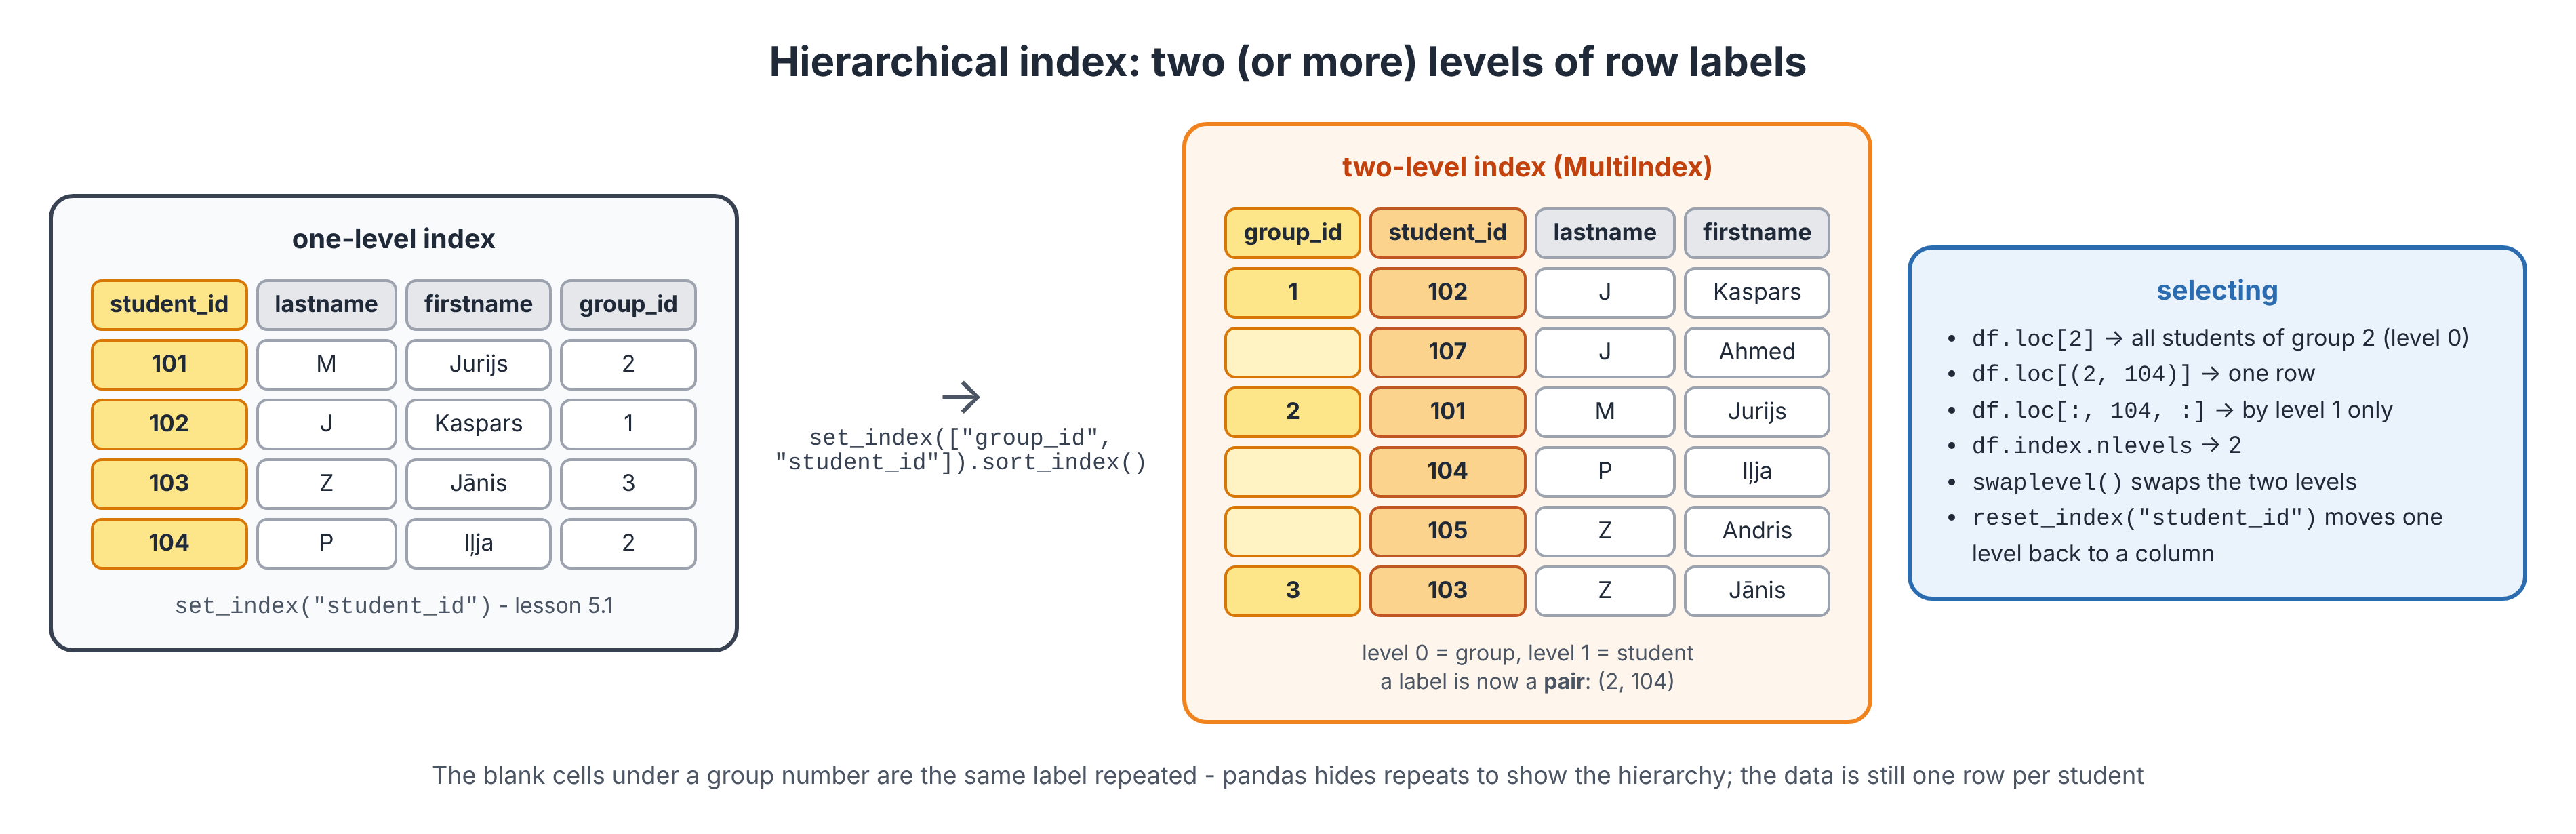

### Multi-index structure

Indexes in pandas data frames are not limited by one sequence:

In [ ]:
results_df.index.nlevels

In [ ]:
results_df.index

`nlevels` = 2; the index itself is a list of **tuples** `(course_id, student_id)` with a name for each level.

### Hierarchical indexing

Two-level index for __students__:

In [ ]:
students_df = students_df.reset_index().set_index(["group_id","student_id"]).sort_index()
students_df

Read the chain: *put `student_id` back as a column → make (`group_id`, `student_id`) the index → sort*. Now the table reads like a class list: group 1 has four students, group 2 four, group 3 six.

### Hierarchical indexing: selectors

In [ ]:
results_df.loc[1] # Selecting by the first-level, course

In [ ]:
results_df.loc[:,103,:] # Selecting by the second-level, student

`loc[1]` - one label for the **outer** level → all results of course 1. `loc[:, 103, :]` - *all courses, student 103, all columns* → the results of one student across courses. A single row is `loc[(1, 103)]` - the full pair as a tuple.

### Rearrange levels

* Change order of levels (__swap__)

In [ ]:
results_df.swaplevel("student_id", "course_id").sort_index().head(10)

### Index to column

* Convert an index level to a column (__reset__)

In [ ]:
results_df.reset_index("student_id").head()

`swaplevel` changes the order of the two levels (student first), `reset_index(level)` moves **one** level back to the columns. Both are handy when a `groupby` with two keys or an `unstack` has produced a MultiIndex you want to flatten - `reset_index()` with no arguments is the universal "make everything a column again".

## Putting it together

The question a dean would ask: *"For every course - how many students have a result, and what is their average attendance?"* Course names are in one table, results in another, so: **merge** the names onto the results, **groupby** course, **agg** two statistics. Three operations from today, one report:

In [ ]:
report = (pd.merge(results_df.reset_index(), courses_df, left_on="course_id", right_index=True, how="right")
            .groupby("course_name")
            .agg(n_students=("student_id", "count"), mean_attendance=("attendance", "mean"))
            .round(1)
            .sort_values("mean_attendance", ascending=False))
report

## Summary

* **concat([df1, df2])** - more rows of the same kind; `join="inner"` common columns only; `keys=[...]` remembers the source; `axis=1` side by side
* **merge(left, right, on= / left_on= right_on= / right_index=True, how=inner|left|right|outer)** - more columns from another table; check `shape` after a join, `validate="many_to_one"` catches bad keys
* **groupby(key)** = split → apply → combine; `.mean() .count() .size()`; `["col"]` to aggregate one column; `agg(["min","max"])`, `agg({"col": [...]})`, `agg(name=("col","stat"))`; `first()/last()` take per-column values, `nth()` takes whole rows
* **reshape**: `melt(id_vars=...)` (columns → one value per row, long) / `pivot(index, columns, values)` (back); `unstack` / `stack` do the same for index levels (stack drops NaN)
* **MultiIndex**: `set_index([a, b])` - a row label made of two parts; `loc[outer]`, `loc[:, inner, :]`, `loc[(a, b)]`; `reset_index()` flattens it
* missing values: `NaN` appears wherever a combination does not exist; `count()` skips them, `size()` does not; fill a specific column with `fillna(0)` when a zero is meant

# Thank you